# 07-04 - Flows and the Crowd

You draw a city's flows, fit two models to Princeton's in-commuters, and measure what location data reveals and what publishing it in aggregate protects.

First Porto's flows and their lengths. Then Princeton's in-commuters under two models, and the region's pairs with their zeros. Then how few points single out a taxi-day or a park visitor, home and work as a key, a hashed medallion, the park published as P07 will be, and noise. At the end you change the minimum count.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import mob_tools as mob

plt.rcParams["figure.dpi"] = 72

scene = json.load(open("data/scene.json"))
reference = json.load(open("data/ground_truth.json"))["p07"]
rules, anchors, lecture = scene["rules"], scene["anchors"], scene["lecture"]
print(f"Princeton's networks of {scene['snapshot']['graphs']} through osmnx {scene['snapshot']['osmnx']} in "
      f"{scene['crs']}; the specimen {reference['traces']['kp2']['fixes']:,} fixes; the stay rule "
      f"{rules['stay']['dist_m']:g} m and {rules['stay']['min_s'] / 60:g} minutes; the class's counts are "
      f"{'published' if reference['class_traces']['published'] else 'not published yet'}")

Princeton's networks of 2026-10-30 through osmnx 2.1.1 in EPSG:26918; the specimen 8,918 fixes; the stay rule 50 m and 10 minutes; the class's counts are not published yet


## Porto's flows and their lengths

The cell reads a year of taxi trips counted on cells of 500 m, draws the 300 largest flows, and lays the phones' displacement law over the trips' lengths.

1,674,152 trips, 1,459,889 on the grid; the 300 largest flows carry 26% of the trips between cells; the median trip runs 4.0 km, the tail above 10 km 3.48, the phones' 1.75


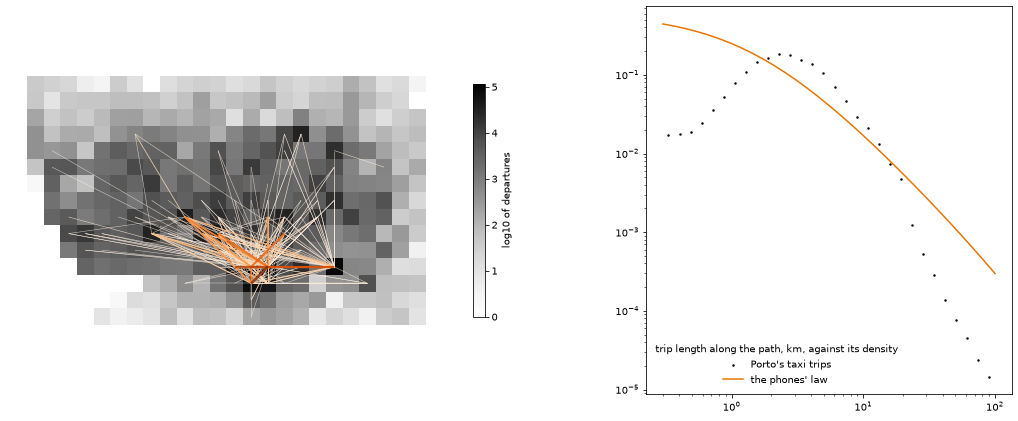

In [2]:
z, lengths = np.load("data/porto_od.npz"), json.load(open("data/porto_lengths.json"))["path_km"]
od, cells = z["od_500m"], mob.make_grid(tuple(z["bounds"]), float(z["cells_m"][0]), crs=str(z["crs"]))
lines = mob.desire_lines(od, cells, min_n=int(np.sort((od - np.diag(np.diag(od))).ravel())[-300]))
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1.5, 1]})
mob.show_access(cells, np.log10(1 + od.sum(axis=1)), axes[0], cmap="Greys", label="log10 of departures")
mob.show_flows(lines, axes[0])
mob.show_loglog(np.array(lengths["edges"]), np.array(lengths["density"]), axes[1], label="Porto's taxi trips")
axes[1].plot(lengths["edges"], mob.gonzalez_pdf(lengths["edges"]), color="#e77500", label="the phones' law")
axes[1].legend(frameon=False, title="trip length along the path, km, against its density")
print(f"{z['n_trips']:,} trips, {z['n_inside_500m']:,} on the grid; the {len(lines)} largest flows carry "
      f"{lines['n'].sum() / (od.sum() - np.trace(od)):.0%} of the trips between cells; the median trip runs "
      f"{lengths['median']:.1f} km, the tail above 10 km {lengths['fit']['alpha']:.2f}, the phones' 1.75")

An origin-destination matrix counts the trips from zone i to zone j. Porto's 300 largest flows run between the centre, the station and the airport and carry a quarter of the trips between cells, and the thousands of thin pairs that carry the rest stay invisible. On the right, the trip lengths run close to the phones' law between 2 and 10 km and fall far more steeply above, because a taxi's trips end where the city ends. A taxi's trips are a car's days, not a person's.

## Princeton's in-commuters

The cell reads the town's jobs by the home tract of their holders, prints where the in-commuters come from, and draws every home tract sized by the commuters it sends.

26,709 jobs in the town, 3,071 held by residents and 23,638 by in-commuters; 9,219 residents work elsewhere
from New Jersey 19,894, Pennsylvania 2,530, further 1,214; Hamilton Township (Mercer) sends 1,642   reference 19,894, 2,530, 1,214, 1,642


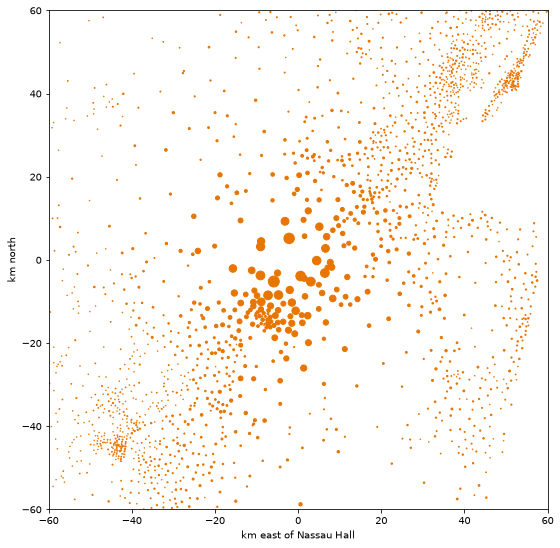

In [3]:
home = pd.read_csv("data/princeton_inflow.csv.gz", dtype={"tract": str})
town, rf, nh = lecture["lodes"]["town"], reference["flows"]["princeton"], anchors["nassau_hall"]
inc, state = town["in_commuters_home_outside_princeton"], home.groupby("state")["inflow"].sum()
nj = home[home["state"] == "NJ"].groupby("municipality")["inflow"].sum()
fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter((home["x"] - nh["x"]) / 1000, (home["y"] - nh["y"]) / 1000, s=home["inflow"] / 3, color="#e77500")
ax.set(xlim=(-60, 60), ylim=(-60, 60), aspect="equal", xlabel="km east of Nassau Hall", ylabel="km north")
print(f"{town['jobs_wac']:,} jobs in the town, {town['live_and_work_in_princeton']:,} held by residents and "
      f"{inc:,} by in-commuters; {town['residents_working_elsewhere']:,} residents work elsewhere")
print(f"from New Jersey {state['NJ']:,}, Pennsylvania {state['PA']:,}, further {inc - state.sum():,}; "
      f"{nj.idxmax()} sends {nj.max():,}   reference {rf['by_state']['NJ']:,}, {rf['by_state']['PA']:,}, "
      f"{rf['unplaced']:,}, {rf['top_municipality'][1]:,}")

The Census Bureau's employment statistics join every job's workplace block to its holder's home block. The map is one column of that matrix, the commuters into the town from every home tract in the 120 km square around Nassau Hall, a dot's area its count. The large dots surround the town and run toward Trenton in the southwest and New Brunswick in the northeast. The counts are jobs, synthetic at the home block and noisy at the work block, so a sum over tracts is the number to quote.

## Princeton's pull by distance

The cell rates every home tract's commuters per thousand of its resident workers, pools the rate in bands of distance, and finds the radius that holds half of the in-commuters.

per thousand resident workers 84 within 5 km, 3.3 at 35 to 40 km, 0.8 at 60 to 80 km; half live within 24 km   reference 84, 3.3, 0.8, 24


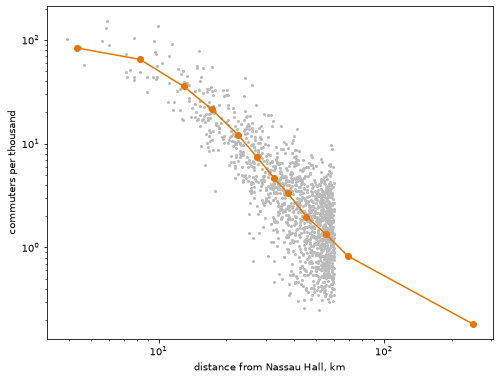

In [4]:
edges = [float(e) for e in lecture["princeton"]["band_edges_km"]]          # the last edge, inf, is text
bands = mob.rate_by_band(home["dist_km"], home["inflow"], home["residents"], edges)
order, rate, rb = home.sort_values("dist_km"), bands["rate"], pd.DataFrame(rf["bands"])["rate"]
half = order["dist_km"].iloc[np.searchsorted(order["inflow"].cumsum() / inc, 0.5)]
w = home[(home["dist_km"] <= 60) & (home["residents"] > 0)]
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(w["dist_km"], 1000 * w["inflow"] / w["residents"], s=4, color="#bbbbbb")
ax.plot(bands["mean_km"], rate, "o-", color="#e77500")
ax.set(xscale="log", yscale="log", xlabel="distance from Nassau Hall, km", ylabel="commuters per thousand")
print(f"per thousand resident workers {rate[0]:.0f} within 5 km, {rate[7]:.1f} at 35 to 40 km, "
      f"{rate[10]:.1f} at 60 to 80 km; half live within {half:.0f} km   reference {rb[0]:.0f}, {rb[7]:.1f}, "
      f"{rb[10]:.1f}, {rf['half_km']:.0f}")

A tract sends commuters in proportion to its resident workers, so the rate per thousand of them is the town's pull at the tract's distance. The grey dots are the home tracts within 60 km, the orange line the bands over all tracts. The pull falls by a factor of 25 between the nearest band and 35 to 40 km, and the thin floor beyond 60 km is where the file's noise and remote work live. The tracts that send nobody sit off the logarithmic axis.

## One destination, one exponent

The cell fits the gravity model to the town's column within 60 km with a power and an exponential decay, then once more with the residents' exponent left free.

1,598 tracts send 19,550; power 1.85, CPC 0.74   reference 1,598, 19,550, 1.85, 0.74
exponential 0.088 a km, halving every 7.9 km, CPC 0.76   reference 0.088, 7.9, 0.76
the residents' own exponent, fitted free, 1.01   reference 1.01


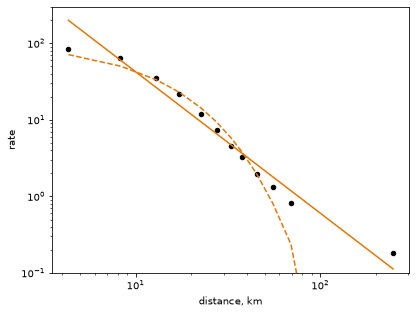

In [5]:
T, m, d, rp, rx, rw = w["inflow"], w["residents"], w["dist_km"], rf["power"], rf["exponential"], rf["window"]
power, pred = mob.gravity_fit_destination(T, m, d, decay="power")
expo, pred_e = mob.gravity_fit_destination(T, m, d, decay="exp")
free = mob.gravity_fit_destination(T, m, d, free_exponent=True)[0]
ax = bands.plot.scatter("mean_km", "rate", loglog=True, ylim=(0.1, 300), color="k", xlabel="distance, km")
ax.plot(bands["mean_km"], 1000 * power["K"] * bands["mean_km"] ** -power["gamma"], color="#e77500")
ax.plot(bands["mean_km"], 1000 * expo["K"] * np.exp(-expo["beta"] * bands["mean_km"]), "--", color="#e77500")
print(f"{len(w):,} tracts send {T.sum():,}; power {power['gamma']:.2f}, CPC {mob.cpc(T, pred):.2f}"
      f"   reference {rw['tracts']:,}, {rw['commuters']:,}, {rp['gamma']:.2f}, {rp['cpc']:.2f}")
print(f"exponential {expo['beta']:.3f} a km, halving every {expo['half_km']:.1f} km, CPC "
      f"{mob.cpc(T, pred_e):.2f}   reference {rx['beta']:.3f}, {rx['half_km']:.1f}, {rx['cpc']:.2f}")
print(f"the residents' own exponent, fitted free, {free['a']:.2f}   reference {rf['residents_exponent']:.2f}")

The gravity model makes the flow from i to j proportional to the resident workers of i and the jobs of j, each to an exponent, times a falling function of distance. With one destination the jobs are one number inside the constant K, and the residents enter as they are, their free exponent being near one. One exponent remains, the slope of the solid line, and K matches the total; the dashed line is the exponential. CPC, the common part of commuters, is one for a perfect prediction.

## The radiation model, nothing fitted

The cell computes the radiation model's flow from every home tract into the town, prints the circle of the tract that sends the most, and draws both models.

tract 34021003301 of Lawrence Township (Mercer), 7.8 km out, sends 361; its circle holds 44,561, the model sends 84 of 3,269   reference 361, 44,561, 84


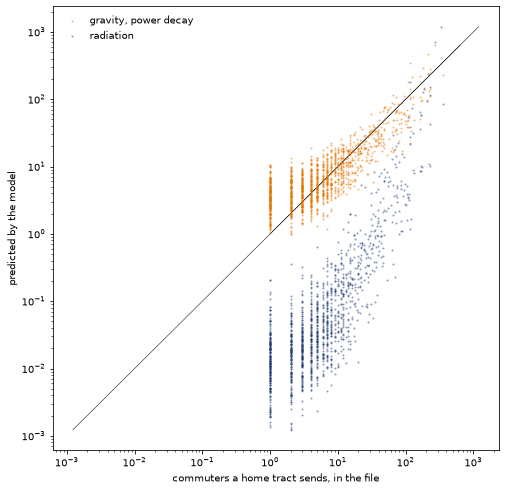

In [6]:
rad, s = mob.radiation_to(home["residents"], home[["x", "y"]], (nh["x"], nh["y"]), town["jobs_wac"],
                          home["out_commuters"])
w = w.assign(gravity=pred, radiation=rad[w.index], s=s[w.index])
top, rc = w.loc[w["inflow"].idxmax()], rf["circle"]
fig, ax = plt.subplots(figsize=(8, 8))
mob.show_scatter_fit(T, w["gravity"], ax, colour="#e77500", label="gravity, power decay")
mob.show_scatter_fit(T, w["radiation"], ax, colour="#1f3b73", label="radiation")
ax.set(xlabel="commuters a home tract sends, in the file", ylabel="predicted by the model")
ax.legend(frameon=False)
print(f"tract {top['tract']} of {top['municipality']}, {top['dist_km']:.1f} km out, sends {top['inflow']}; "
      f"its circle holds {top['s']:,.0f}, the model sends {top['radiation']:.0f} of {top['out_commuters']:,}"
      f"   reference {rc['inflow']}, {rc['s']:,.0f}, {rc['predicted']:.0f}")

The radiation model of 2012 fits nothing. A commuter takes the nearest job whose random offer beats the best offer at home, so a tract's flow depends on its resident workers, the commuters who leave it, the town's jobs and s, the resident workers of the tracts closer to it than the town. Tract 33.01 in Lawrence has a circle of 44,561 workers, and the model sends about a quarter of what the file counts. The blue points lie far below the black diagonal for all but the town's neighbours.

## Where each model fails

The cell scores the radiation model on the commuters within 60 km, then sums the gravity model's predictions by municipality and prints its largest misses.

radiation 4,130 of 19,550, CPC 0.23, rescaled 0.34   reference 4,130, 0.23, 0.34
Hamilton Township (Mercer) 1,642 against 973; Ewing 909 against 410; West Windsor 872 against 1,572; Plainsboro 737 against 1,160; Pennsylvania 2,034 against 2,918
reference Hamilton Township (Mercer) 1,642 against 973; Ewing 909 against 410; West Windsor 872 against 1,572; Plainsboro 737 against 1,160; Pennsylvania 2,034 against 2,918


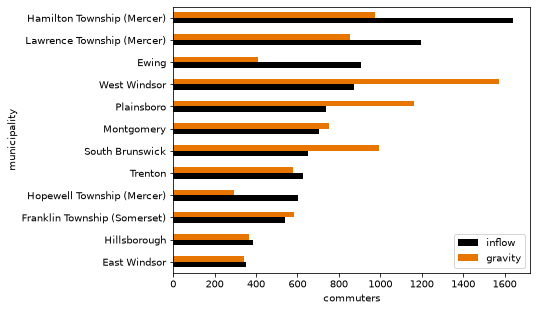

In [7]:
rr = rf["radiation"]
by = w[w["state"] == "NJ"].groupby("municipality")[["inflow", "gravity"]].sum()
by["excess"], pa = by["inflow"] - by["gravity"], w[w["state"] == "PA"]
four = by.sort_values("excess").iloc[[-1, -2, 0, 1]]
by.sort_values("inflow")[["inflow", "gravity"]].tail(12).plot.barh(color=["k", "#e77500"], xlabel="commuters")
print(f"radiation {w['radiation'].sum():,.0f} of {T.sum():,}, CPC {mob.cpc(T, w['radiation']):.2f}, rescaled "
      f"{mob.cpc(T, w['radiation'] * T.sum() / w['radiation'].sum()):.2f}   reference "
      f"{rr['predicted']:,.0f}, {rr['cpc']:.2f}, {rr['cpc_rescaled']:.2f}")
print("; ".join(f"{name} {r['inflow']:,.0f} against {r['gravity']:,.0f}" for name, r in four.iterrows())
      + f"; Pennsylvania {pa['inflow'].sum():,.0f} against {pa['gravity'].sum():,.0f}")
print("reference " + "; ".join(f"{a} {b:,} against {c:,}" for a, b, c in rf["above"] + rf["below"])
      + f"; Pennsylvania {rf['pennsylvania']['inflow']:,} against {rf['pennsylvania']['gravity']:,}")

The radiation model predicts a fifth of the commuters, and scaled to the file's total it still scores far below gravity. The gravity model's residuals show where distance is not the whole story. Hamilton Township and Ewing send far more than predicted, West Windsor and Plainsboro far fewer, and Pennsylvania fewer across the Delaware. Jobs at home do not settle it, as West Windsor holds two jobs for every resident worker and Hamilton fewer than one. The model sees size and distance, not roads, rivers or house prices.

## The region's pairs, zeros included

The cell fits the pooled gravity model to every ordered pair of the region's 453 tracts, a zero where no flow is listed, and to the listed pairs alone.

In [8]:
pairs = pd.read_csv("data/lodes_tracts.csv.gz").query("dist_km > 0.5")
totals, rg = pd.read_csv("data/lodes_tract_totals.csv.gz"), reference["flows"]["lodes"]["complete"]
D = np.hypot(totals[["x"]].values - totals["x"].values, totals[["y"]].values - totals["y"].values) / 1000
obs = (pairs.pivot(index="h_tract", columns="w_tract", values="S000")
       .reindex(index=totals["tract"], columns=totals["tract"]).fillna(0).to_numpy())
(N, M), keep, listed = np.meshgrid(totals["jobs"], totals["residents"]), D > 0.5, obs > 0
fit, gp = mob.gravity_fit(obs[keep], M[keep], N[keep], D[keep])
fit_l, gp_l = mob.gravity_fit(obs[listed], M[listed], N[listed], D[listed])
print(f"{keep.sum():,} ordered pairs, {(keep & ~listed).sum():,} of them zero; exponents {fit['a']:.2f}, "
      f"{fit['b']:.2f}, {fit['gamma']:.2f}, CPC {mob.cpc(obs[keep], gp):.2f}; the listed pairs alone "
      f"{fit_l['gamma']:.2f}, CPC {mob.cpc(obs[listed], gp_l):.2f}   reference {rg['a']:.2f}, {rg['b']:.2f}, "
      f"{rg['gamma']:.2f}, {rg['cpc']:.2f}, {reference['flows']['lodes']['listed']['cpc']:.2f}")

204,750 ordered pairs, 111,331 of them zero; exponents 1.16, 0.95, 1.03, CPC 0.66; the listed pairs alone 0.86, CPC 0.73   reference 1.16, 0.95, 1.03, 0.66, 0.73


Pooled over a region the gravity model has three exponents, for the residents, the jobs and the distance. A flow the file does not list is a zero, and a model fitted to the listed pairs alone never sees the pairs nobody travels between, which flatters it. With the zeros every exponent grows and the score falls. The region's distance exponent is near one and Princeton's column falls with nearly two, because an exponent belongs to its scale and to the pairs it is fitted on.

## Why small tracts defeat the circle

The cell runs the radiation model on the same pairs, scores it, and sums the observed and predicted flows in bands of 5 km.

radiation CPC 0.19; 4.8 times the flow within 5 km, 3% of it beyond 20 km   reference 0.19, 4.8, 3%


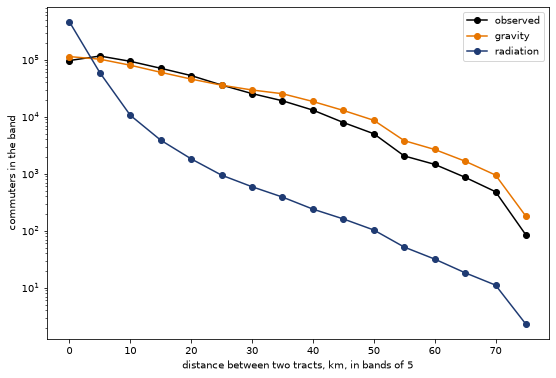

In [9]:
rad_r = mob.radiation(totals["residents"], totals[["x", "y"]], obs.sum(axis=1))[keep]
b = pd.DataFrame({"observed": obs[keep], "gravity": gp, "radiation": rad_r}).groupby(D[keep] // 5 * 5).sum()
ax = b.plot(logy=True, marker="o", color=["#000000", "#e77500", "#1f3b73"], figsize=(9, 6))
ax.set(xlabel="distance between two tracts, km, in bands of 5", ylabel="commuters in the band")
print(f"radiation CPC {mob.cpc(obs[keep], rad_r):.2f}; "
      f"{b.loc[0, 'radiation'] / b.loc[0, 'observed']:.1f} times the flow within 5 km, "
      f"{b.loc[20:, 'radiation'].sum() / b.loc[20:, 'observed'].sum():.0%} of it beyond 20 km"
      f"   reference {rg['radiation_cpc']:.2f}, {rg['radiation_near']:.1f}, {rg['radiation_far']:.0%}")

Census tracts are small and alike, so the circle between near neighbours holds almost nobody and the radiation model sends a tract's commuters next door. It overshoots the pairs within 5 km several times over and gives the pairs beyond 20 km a few percent of their flow, which is the blue line crossing the black one. Masucci and colleagues measured this weakness at fine scales on England and Wales in 2013. A model without a parameter makes a strong claim, and here the claim fails.

## Unique in the crowd

The cell writes out the unicity test for one taxi-day, runs it on every taxi-day with two and four random points, and reads the lecture's curve over four cell sizes.

one taxi-day of 19 points; four drawn points shared by [3382, 1483, 720, 266] others, together by [3382, 30, 0, 0]   reference [3382, 1483, 720, 266], [3382, 30, 0, 0]


2 points identify 9% of 140,975 taxi-days   reference 9%


4 points identify 94% of 140,975 taxi-days   reference 94%
per halving of the cell's area at four points 2.4, 15.3, 54.7 percent lost   reference 2.4, 15.3, 54.7


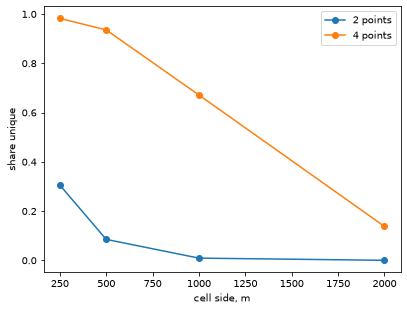

In [10]:
pts, ru = np.load("data/porto_points.npz"), reference["privacy"]["uniqueness"]
ex = mob.example_uniqueness(pts["user"], pts["cell"], pts["hour"], p=4)
print(f"one taxi-day of {ex['n_points']} points; four drawn points shared by {ex['sharers']} others, "
      f"together by {ex['together']}   reference {ru['example']['sharers']}, {ru['example']['together']}")
for p in (2, 4):
    u = mob.uniqueness(pts["user"], pts["cell"], pts["hour"], p=p, min_points=rules["unique_min_points"])
    print(f"{p} points identify {u['share']:.0%} of {u['n_users']:,} taxi-days   reference {ru[f'p{p}']:.0%}")
curve = pd.DataFrame(ru["curve"]).rename(columns={"p2": "2 points", "p4": "4 points"})
curve.plot(x="cell_m", y=["2 points", "4 points"], marker="o", xlabel="cell side, m", ylabel="share unique")
drops = [f"{h['drop_pct']:.1f}" for h in mob.halving_factors(curve["cell_m"], curve["4 points"])]
print(f"per halving of the cell's area at four points {', '.join(drops)} percent lost   reference "
      f"{', '.join(f'{v:.1f}' for v in ru['halving_drop_pct'])}")

A record is a set of points, a cell and an hour each, and is unique when no other record holds all the points drawn from it. The taxi-day above shares each point with 266 to 3,382 others, the first two with 30 and all four with nobody. Four points singled out 95 percent of 1.5 million phones in 2013, each halving of the resolution costing 9.3 percent. Porto's curve falls off a cliff, because 24 cells of 2 km hold the whole city. A taxi-day is not a person.

## A small crowd hides nobody

The cell reads the fifteen visitors of one theme park, counts the distinct visitors in every 10 m cell, and runs the unicity test at 25 m and the hour.

1,700 lit cells of 10 m, 30% of them hold one visitor   reference 1,700, 30%
at 25 m and the hour two points single out 78% of the 15 visitors, four 99%   reference 78%, 99%


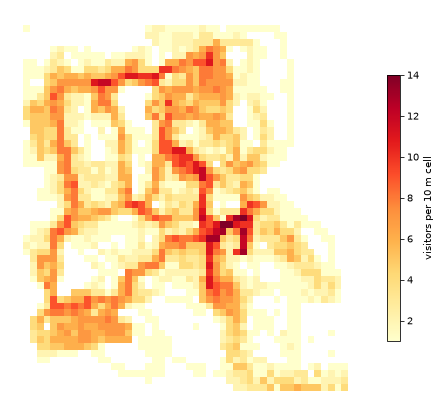

In [11]:
park, pk, rk = pd.read_csv("data/themepark_kbf_fixes.csv.gz"), lecture["park"], reference["privacy"]["park"]
box, who, g10 = pk["box"], park["participant_id"], mob.make_grid(pk["box"], 10.0, crs=pk["crs"])
x, y = park["x"].clip(box[0], box[2] - 0.01), park["y"].clip(box[1], box[3] - 0.01)  # held at the box edge
heat = mob.distinct_per_cell(who, mob.cell_of(g10, x, y), n_cells=len(g10))
cell, hour = mob.cell_hours(mob.make_grid(box, 25.0, crs=pk["crs"]), x, y, park["t_s"])
unique = [mob.uniqueness(who, cell, hour, p=p, draws=200)["share"] for p in (2, 4)]
fig, ax = plt.subplots(figsize=(8, 8))
mob.show_access(g10, np.where(heat > 0, heat, np.nan), ax, cmap="YlOrRd", label="visitors per 10 m cell")
print(f"{(heat > 0).sum():,} lit cells of 10 m, {(heat[heat > 0] == 1).mean():.0%} of them hold one visitor"
      f"   reference {rk['heat']['lit_cells']:,}, {rk['heat']['single']:.0%}")
print(f"at 25 m and the hour two points single out {unique[0]:.0%} of the {who.nunique()} visitors, four "
      f"{unique[1]:.0%}   reference {rk['uniqueness']['p2']:.0%}, {rk['uniqueness']['p4']:.0%}")

Fifteen visitors over one afternoon are the size of Wednesday's crowd. A heatmap of distinct visitors per cell looks like an aggregate, but a pale cell that one visitor alone lit draws that visitor's way, the side path to a ride nobody else took. That is how the Strava heatmap of 2017 drew soldiers' routes on remote bases. At 25 m and the hour two points single out most visitors and four nearly all, because in so small a crowd hardly anyone shares a corner at the same hour.

## Home, work and a hashed key

The cell counts the workers who share each pair of home and work area among the town's jobs at three levels, then hashes every key of two medallion formats.

In [12]:
jobs = pd.read_csv("data/lodes_blocks_princeton.csv.gz", dtype={"w_geocode": str, "h_geocode": str})
for level, n in (("block", 15), ("tract", 11), ("county", 5)):
    a = mob.anonymity_sets(zip(jobs["w_geocode"].str[:n], jobs["h_geocode"].str[:n]), weights=jobs["S000"])
    rh = reference["privacy"]["homework"][level]
    print(f"by {level} {a['keys']:,} pairs, {a['alone_keys']:.1%} with one worker, {a['alone_people']:.1%} "
          f"of workers alone, median {a['median']:,.0f}   reference {rh['pairs']:,}, "
          f"{rh['alone_pairs']:.1%}, {rh['alone_workers']:.1%}, {rh['median']:,.0f}")
hk, ks = mob.hash_keys(["9A99", "AA999"], example="5X55"), reference["privacy"]["aggregation"]["key_space"]
full = sum(mob.key_space(f) for f in ("9A99", "AA999", "AAA999"))
print(f"{hk['keys']:,} keys hashed with MD5 in {hk['seconds']:.1f} s; {hk['example_digest'][:12]} is "
      f"{hk['found'][hk['example_digest']]} again; the three formats hold {full:,} keys, about "
      f"{full / hk['per_second']:.0f} s at this rate   reference {ks['timed_keys']:,}, {ks['total']:,}")

by block 22,643 pairs, 91.9% with one worker, 77.9% of workers alone, median 1   reference 22,643, 91.9%, 77.9%, 1
by tract 7,677 pairs, 57.8% with one worker, 16.6% of workers alone, median 9   reference 7,677, 57.8%, 16.6%, 9
by county 192 pairs, 36.5% with one worker, 0.3% of workers alone, median 2,292   reference 192, 36.5%, 0.3%, 2,292


702,000 keys hashed with MD5 in 0.4 s; 9d742f1eafe3 is 5X55 again; the three formats hold 18,278,000 keys, about 10 s at this rate   reference 702,000, 18,278,000


The anonymity set of a home and work pair is the crowd a worker hides in once both are known. By census block most of the town's workers are alone in theirs, as Golle and Partridge found nationally in 2009. The Census publishes such pairs without a minimum count, since its home side is synthesised and its work side noisy, so a pair of one is a synthetic worker. New York's hashed taxi medallions of 2014 fell to a table of every possible key, which a laptop builds in seconds.

## Published as P07 will be

The cell counts distinct visitors per cell and hour on cells of 25 m and 100 m, keeps the counts at or above k, and suppresses Porto's small pairs.

In [13]:
for size in (25.0, 100.0):
    cs, hs = mob.cell_hours(mob.make_grid(box, size, crs=pk["crs"]), x, y, park["t_s"])
    lit, rs = mob.published_counts(cs, hs, k=1, ids=who)[1], rk["release"][f"{size:g}"]
    print(f"{size:g} m, {(lit > 0).sum():,} lit cell-hours; k 10 keeps {(lit >= 10).sum()}, k 5 keeps "
          f"{(lit >= 5).sum()}, {(lit[lit > 0] >= 5).mean():.1%}   reference {rs['lit_cell_hours']:,}, "
          f"{rs['k']['10']['cell_hours']}, {rs['k']['5']['cell_hours']}, {rs['k']['5']['share']:.1%}")
lost = [f"{(z[g][z[g] > 0] < rules['agg_k']).mean():.0%}" for g in ("od_500m", "od_1km", "od_2km")]
ref = [f"{v['suppressed_share']:.0%}" for v in reference["privacy"]["aggregation"]["grids"].values()]
print(f"Porto loses {', '.join(lost)} of its pairs at 500 m, 1 km and 2 km   reference {', '.join(ref)}")
counts_file = "data/" + reference["class_traces"]["file"]
counts = pd.read_csv(counts_file) if reference["class_traces"]["published"] else None
print("the class's counts are not published yet" if counts is None else f"{len(counts):,} class cell-hours")

25 m, 1,430 lit cell-hours; k 10 keeps 0, k 5 keeps 48, 3.4%   reference 1,430, 0, 48, 3.4%
100 m, 172 lit cell-hours; k 10 keeps 1, k 5 keeps 33, 19.2%   reference 172, 1, 33, 19.2%
Porto loses 64%, 39%, 10% of its pairs at 500 m, 1 km and 2 km   reference 64%, 39%, 10%
the class's counts are not published yet


This is the course's release for Wednesday's traces, counts of trackers per cell and hour at or above a minimum k and nothing else, no noise and no line one person walked. k counts people, never days or fixes, and is chosen before the trackers go out. At k of 10 the fifteen visitors publish nothing, and coarser cells keep more. Porto keeps a third of its pairs even at 500 m, because a city hides more people than a park. The last line reads the class's counts once published.

## Noise on one count

The cell releases the park's busiest cell-hour and Porto's busiest 1 km pair a hundred times each under Laplace noise at budgets of 1 and 0.1.

budget 1, 7 visitors between 3.5 and 11.8, off by 1.1; 21,881 trips between 21,876 and 21,884   reference 3.5, 11.8, 1.1, 21,876, 21,884
budget 0.1, 7 visitors between -42.6 and 52.1, off by 10.2; 21,881 trips between 21,832 and 21,921   reference -42.6, 52.1, 10.2, 21,832, 21,921


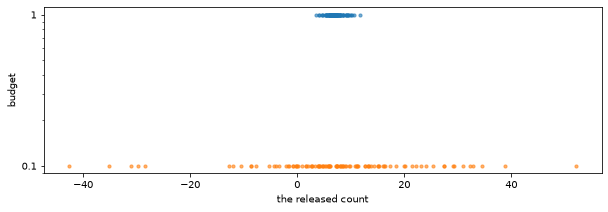

In [14]:
lit25, od1 = mob.published_counts(cell, hour, k=1, ids=who)[1], z["od_1km"] - np.diag(np.diag(z["od_1km"]))
fig, ax = plt.subplots(figsize=(10, 3))
ax.set(yscale="log", yticks=[0.1, 1], yticklabels=["0.1", "1"], ylabel="budget", xlabel="the released count")
for budget, j in (("1", 0), ("0.1", 1)):
    visitors = mob.laplace_noise(lit25.max(), epsilon=float(budget), seed=mob.SEED + j)
    trips = mob.laplace_noise(od1.max(), epsilon=float(budget), seed=mob.SEED + 10 + j)
    rpark, rporto = rk["laplace"][budget], reference["privacy"]["aggregation"]["laplace"]["budgets"][budget]
    print(f"budget {budget}, {lit25.max()} visitors between {visitors.min():.1f} and {visitors.max():.1f}, "
          f"off by {abs(visitors - lit25.max()).mean():.1f}; {od1.max():,} trips between {trips.min():,.0f} "
          f"and {trips.max():,.0f}   reference {rpark['min']:.1f}, {rpark['max']:.1f}, "
          f"{rpark['mean_abs_error']:.1f}, {rporto['min']:,.0f}, {rporto['max']:,.0f}")
    ax.scatter(visitors, np.full(100, float(budget)), s=10, alpha=0.6)

Differential privacy asks that the probability of any outcome change by at most a factor of e to the epsilon when one person's data changes. The Laplace mechanism adds noise of scale sensitivity over epsilon, here one count, so seven visitors become unreadable at 0.1 and 21,881 trips barely move. A sensitivity of one trip protects trips, not people. Google's mobility reports of 2020 used Laplace noise of scale 9.09 for states and 4.55 for counties, a budget of 0.44 per place visit and at most 2.64 a day.

## Your turn

The park was published at a minimum count of ten, with Porto's matrix on cells of 500 m as the contrast. The bars are the lit and the published cell-hours by hour. Lower K to three and read the cell-hours, the share and the cells the park publishes, and Porto's published pairs. Run the cell as it is, then change the marked value and run it again.

What does a minimum count of three buy and what does it cost for a crowd the size of Wednesday's, and what does the same change do to Porto's matrix? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

at a minimum count of 10 the park publishes 0 of 1,430 cell-hours (0%) in 0 cells; Porto publishes 16,432 of 45,047 pairs on cells of 500 m


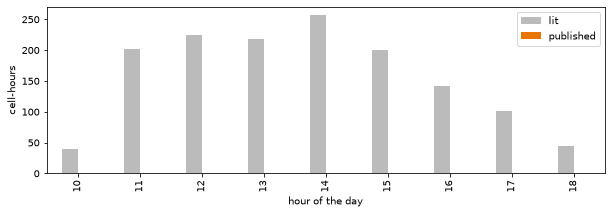

In [15]:
K = 10  # change me: 3
kept, m500 = lit25 >= K, z["od_500m"]
by_hour = pd.DataFrame({"lit": (lit25 > 0).sum(axis=0), "published": kept.sum(axis=0)})
by_hour[by_hour["lit"] > 0].plot.bar(color=["#bbbbbb", "#e77500"], figsize=(10, 3), xlabel="hour of the day",
                                     ylabel="cell-hours")
print(f"at a minimum count of {K} the park publishes {kept.sum()} of {(lit25 > 0).sum():,} cell-hours "
      f"({kept.sum() / (lit25 > 0).sum():.0%}) in {kept.any(axis=1).sum()} cells; Porto publishes "
      f"{(m500 >= K).sum():,} of {(m500 > 0).sum():,} pairs on cells of 500 m")

## Check your understanding

1. Princeton's column falls with an exponent of 1.85 and the region's pairs with 1.03. Why can both be right, and which would you use for one new office in town?
2. The radiation model fits nothing and loses on both sets of pairs. What does the circle between two neighbouring tracts hold, and where might the model do better?
3. Four points single out 94 percent of Porto's taxi-days and 99 percent of the park's visitors. Which four points of your own Wednesday would single you out?
4. What does k count in the class's release, and why is it chosen before the trackers go out rather than after?

## Where we are

You have drawn a city's flows, fitted the gravity model to Princeton's in-commuters and to the region's pairs, scored the radiation model beside it, counted how few points single out a taxi-day or a visitor, measured home and work as a key, hashed a key space, published a small crowd at a minimum count as the class's traces will be, and noised one count. An origin-destination matrix is a weighted graph over places. Lecture 08 begins there and turns the graph over places and roads into the input of a model.

## Further resources

Nothing in this course requires anything below.

- A universal model for mobility and migration patterns, Filippo Simini and colleagues, Nature 2012, https://doi.org/10.1038/nature10856
- Unique in the Crowd: the privacy bounds of human mobility, Yves-Alexandre de Montjoye and colleagues, Scientific Reports 2013, https://doi.org/10.1038/srep01376
- Human mobility: models and applications, Hugo Barbosa and colleagues, Physics Reports 2018, sections 3 and 4, https://arxiv.org/abs/1710.00004
- LEHD Origin-Destination Employment Statistics, the technical documentation of LODES8, https://lehd.ces.census.gov/data/lodes/LODES8/

The tables, numbers and this kit are the course's own work, published under CC BY 4.0. The theme-park fixes, coded stops and park layers are the dataset of Utley and Hackl 2026, CC BY 4.0, doi 10.5281/zenodo.20748587, recorded with the visitors' consent and published as codes. Porto's taxi trips are the ECML PKDD 2015 challenge data of Moreira-Matias and colleagues, CC BY 4.0, through the UCI Machine Learning Repository; the kit carries counts and cell-hour points, never a trajectory. The commuting flows are LODES8 2023 of the US Census Bureau and the block groups carry ACS 2020 to 2024 estimates, both public domain.